<a href="https://colab.research.google.com/github/ApolloJRAgapolo/GCI-World-April-Final-Assignment-Output/blob/main/Company_A_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Improving Customer Retention Through Churn Prediction
### Company A Telecommunications | GCI World April 2026 Final Assignment

**Author:** John Rodmar E. Agapolo  
**Project:** Customer churn prediction

---

## What I wanted to do

In this project, I use customer data to see whether I can predict which customers may leave Company A (`churn = 1`) and which may stay (`churn = 0`). My goal is to see how this information could help the company decide which customers may need a closer look.

The dataset guide says that churn is recorded 31–60 days after the observation date. This means I am using the available customer information to predict a later outcome.

## Steps I followed

1. Load the two CSV files and check that the customer IDs match.
2. Look at missing values and check the data.
3. Compare some customer details between those who stayed and those who churned.
4. Split the data into training, validation, and test sets.
5. Compare a simple baseline, Logistic Regression, Decision Tree, and Random Forest.
6. Check the selected model and use the findings to suggest possible retention actions.

## A note about the results

The model can help identify patterns linked to churn, but it cannot prove why a customer leaves. It also cannot prove that a retention offer will make a customer stay. Before using this model in a real company, the available data and the results would need to be checked with newer customer records.

## Course topics I used

- **Session 5:** supervised learning, Logistic Regression, Decision Trees, splitting data, scaling, and overfitting.
- **Session 8:** one-hot encoding, feature preparation, cross-validation, and ensemble models such as Random Forest.

**Dataset reference:** `ENG_Company_A Dataset Overview.docx`, provided with the assignment. I used it to understand the churn target and the meaning of some columns.

I used Scikit-learn's `Pipeline` and `ColumnTransformer` to keep data preparation and model training together. The missing-value rules and category encoding are learned from the training data, then used on the validation and test data. This helps prevent information from those sets from affecting the training process.


## 1. Import libraries and set the random seed


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

RANDOM_STATE = 42

## 2. Load the CSV files


I saved `Client.csv` and `Record.csv` in the Google Drive folder shown in `DATA_DIR` below. If your files are in a different folder, update that path before running the code.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/GCI WORLD FINAL ASSIGNMENT")
CLIENT_PATH = DATA_DIR / "Client.csv"
RECORD_PATH = DATA_DIR / "Record.csv"

if not CLIENT_PATH.exists() or not RECORD_PATH.exists():
    raise FileNotFoundError(
        "Could not find Client.csv and Record.csv. Place both files beside the notebook "
        "or update DATA_DIR to their folder."
    )

client = pd.read_csv(CLIENT_PATH)
record = pd.read_csv(RECORD_PATH)

print("Client dataset shape:", client.shape)
print("Record dataset shape:", record.shape)

Mounted at /content/drive
Client dataset shape: (100000, 50)
Record dataset shape: (100000, 51)


## 3. Check and merge the datasets


In [3]:
KEY = "Customer_ID"
TARGET = "churn"

# Check that both files have the customer ID column.
assert KEY in client.columns and KEY in record.columns, f"{KEY} must exist in both files."

# Check that each file has one row per customer.
print("Duplicate IDs in Client:", client[KEY].duplicated().sum())
print("Duplicate IDs in Record:", record[KEY].duplicated().sum())

assert client[KEY].is_unique, "Client contains duplicate Customer_ID values."
assert record[KEY].is_unique, "Record contains duplicate Customer_ID values."

client_ids = set(client[KEY])
record_ids = set(record[KEY])
print("IDs only in Client:", len(client_ids - record_ids))
print("IDs only in Record:", len(record_ids - client_ids))
assert client_ids == record_ids, "The source files do not contain exactly the same customer IDs."

# Make sure each customer matches one row in each file.
df = client.merge(record, on=KEY, how="inner", validate="one_to_one")

print("Merged dataset shape:", df.shape)
print("Duplicate merged rows:", df.duplicated().sum())
print("Missing target values:", df[TARGET].isna().sum())
print("Target values:", sorted(df[TARGET].dropna().unique().tolist()))

assert TARGET in df.columns, f"Target column {TARGET} is missing."
assert df[TARGET].notna().all(), "The target contains missing values."
assert set(df[TARGET].unique()).issubset({0, 1}), "The target must be binary (0/1)."

df[TARGET] = df[TARGET].astype(int)
df.head()

Duplicate IDs in Client: 0
Duplicate IDs in Record: 0
IDs only in Client: 0
IDs only in Record: 0
Merged dataset shape: (100000, 100)
Duplicate merged rows: 0
Missing target values: 0
Target values: [0, 1]


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,"4,228.000","1,504.620","1,453.440","4,085.000",1602,29.660,83.370,32.690,272,116,30,322.000,136.000,38.000,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.990,2.000,2.000,WCMB,0.000,0.000,O,15.000,S,S,1.000,M,4.000,3.000,C,A,0.000,N,U,U,U,U,U,Y,361.000,1000001,23.997,219.250,22.500,0.247,0.000,0.000,0.000,0.000,0.000,-157.250,-18.997,0.667,0.000,0.667,0.000,6.333,0.000,52.333,0.000,42.333,0.000,45.000,0.000,0.000,0.000,0.000,18.000,0.000,90.643,0.000,97.177,0.000,0.000,0.000,0.000,58.000,0.000,132.600,0.000,24.000,0.000,55.220,0.000,1.333,52.333,45.000,0.000,0.333,1,61
1,1,1,N,EA,N,14654,"26,400.000","2,851.680","2,833.880","26,367.000",14624,51.530,479.400,265.890,305,158,40,477.000,275.000,48.000,U,CHICAGO AREA,N,N,NaN,7.000,6.000,WC,1.000,1.000,NaN,1.000,S,S,1.000,M,5.000,1.000,C,A,0.000,Z,U,U,U,U,U,Y,240.000,1000002,57.492,482.750,37.425,0.247,22.750,9.100,9.100,0.000,0.000,532.250,50.987,8.333,0.000,1.000,0.000,61.333,0.000,263.333,0.000,69.000,0.000,193.333,0.000,1.667,6.333,5.463,53.000,0.333,189.397,0.000,55.280,46.333,24.217,6.333,3.697,83.667,0.000,75.333,0.000,157.000,0.000,169.343,0.000,9.333,263.333,193.333,0.000,5.667,0,56
2,1,1,Y,C,N,7903,"24,385.053","2,155.910","1,934.470","24,303.050",7888,34.540,433.980,140.860,12,7,17,11.000,6.000,17.000,S,GREAT LAKES AREA,N,N,29.990,2.000,1.000,NaN,0.000,0.000,O,7.000,S,M,2.000,M,5.000,2.000,C,A,0.000,N,U,Y,U,U,U,Y,"1,504.000",1000003,16.990,10.250,16.990,0.000,0.000,0.000,0.000,0.000,0.000,-4.250,0.000,0.333,0.000,0.000,0.000,2.667,0.000,9.000,0.000,0.333,0.000,6.000,0.000,0.000,0.000,0.000,0.333,0.000,5.427,0.000,0.000,0.000,0.000,0.000,0.000,5.000,0.000,5.193,0.000,1.000,0.000,0.233,0.000,0.333,9.000,6.000,0.000,0.000,1,58
3,1,1,Y,B,N,1502,"3,065.000","2,000.900","1,941.810","3,035.000",1479,40.450,63.230,30.810,8,3,38,50.000,25.000,40.000,T,CHICAGO AREA,N,N,29.990,1.000,1.000,NaN,0.000,0.000,NaN,6.000,M,M,4.000,M,6.000,1.000,C,D,0.000,U,Y,U,U,U,U,Y,"1,812.000",1000004,38.000,7.500,38.000,0.000,0.000,0.000,0.000,0.000,0.000,-1.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,3.667,0.000,1.333,0.000,3.667,0.000,0.000,0.000,0.000,1.333,0.000,8.410,0.000,0.413,0.333,0.257,0.000,0.000,1.333,0.000,3.380,0.000,3.667,0.000,5.450,0.000,0.000,3.667,3.667,0.000,0.000,0,60
4,1,1,Y,A,N,4485,"14,028.000","2,181.120","2,166.480","13,965.000",4452,38.690,249.380,79.500,558,191,55,586.000,196.000,80.000,U,NEW ENGLAND AREA,Y,N,149.990,6.000,4.000,WCMB,0.000,0.000,R,5.000,M,S,1.000,M,6.000,1.000,C,O,0.000,I,U,U,U,U,U,Y,434.000,1000005,55.230,570.500,71.980,0.000,0.000,0.000,0.000,0.000,0.000,38.500,0.000,9.667,0.000,0.667,0.000,77.000,0.000,222.333,0.000,94.667,0.000,137.000,0.000,8.667,15.000,11.077,66.000,0.000,285.233,0.000,106.330,14.667,10.817,0.667,0.367,97.333,0.000,173.477,0.000,90.333,0.000,218.087,0.000,10.333,222.333,137.000,0.000,0.000,0,57


## 4. Check the data quality


In [4]:
# Check the data types and missing values.
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Numeric columns:", df.select_dtypes(include=np.number).shape[1])
print("Categorical columns:", df.select_dtypes(exclude=np.number).shape[1])

missing_summary = (
    df.isna().sum()
      .to_frame("missing_count")
      .assign(missing_percent=lambda x: x["missing_count"] / len(df) * 100)
      .query("missing_count > 0")
      .sort_values("missing_percent", ascending=False)
)
display(missing_summary.head(20))

Rows: 100000
Columns: 100
Numeric columns: 79
Categorical columns: 21


,missing_count,missing_percent
numbcars,49366,49.366
dwllsize,38308,38.308
HHstatin,37923,37.923
ownrent,33706,33.706
dwlltype,31909,31.909
lor,30190,30.190
income,25436,25.436
adults,23019,23.019
infobase,22079,22.079
hnd_webcap,10189,10.189


Saved: Top 15 Features by Missing-Value Percentage.png


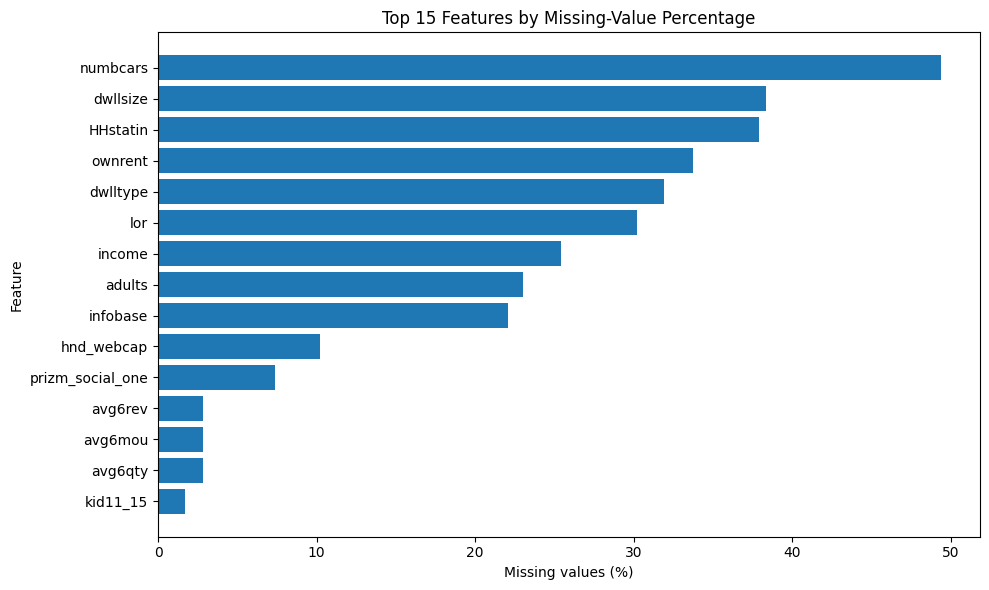

In [34]:
plot_data = missing_summary.head(15).sort_values("missing_percent")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data.index.astype(str), plot_data["missing_percent"].values)
ax.set_title("Top 15 Features by Missing-Value Percentage")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Feature")
plt.tight_layout()

# Save chart
save_chart(fig, "Top 15 Features by Missing-Value Percentage.png")
plt.show()

### What I found

- Each file should have one row for each customer. I check the customer IDs before merging the files.
- `Customer_ID` is only an ID. I leave it out of the model because it does not describe customer activity.
- Some household and customer details have many missing values.
- I fill missing number values with the median and missing category values with the most common value. These values are learned from the training data only.
- Missing values may also tell us something about the data. I could look into this further in a future version.


## 5. Explore churn and customer patterns


In [6]:
churn_counts = df[TARGET].value_counts().sort_index()
churn_summary = pd.DataFrame({
    "customer_count": churn_counts,
    "percentage": (churn_counts / len(df) * 100).round(2),
})
churn_summary.index = ["Stayed (0)", "Churned (1)"]
display(churn_summary)

,customer_count,percentage
Stayed (0),50438,50.440
Churned (1),49562,49.560


Saved: Customer Churn Distribution.png


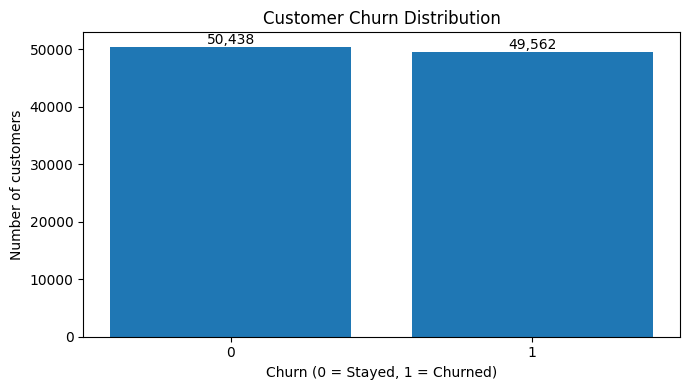

In [33]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(churn_counts.index.astype(str), churn_counts.values)
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn (0 = Stayed, 1 = Churned)")
ax.set_ylabel("Number of customers")
for index, value in enumerate(churn_counts.values):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()

# Save chart
save_chart(fig, "Customer Churn Distribution.png")
plt.show()

### Compare customers who stayed and churned

I compare the selected columns for both groups. These numbers help me spot differences, but they do not prove that a difference is statistically significant or that a feature causes churn.


In [8]:
selected_features = [
    "eqpdays",       # Age of current equipment, in days
    "change_mou",    # Change in monthly minutes of use versus prior three-month average
    "mou_Mean",      # Mean monthly minutes of use
    "rev_Mean",      # Mean monthly revenue
    "custcare_Mean", # Mean customer-care calls
    "months",        # Months in service
]

available_features = [col for col in selected_features if col in df.columns]
summary_rows = []
for feature in available_features:
    for churn_value, label in [(0, "Stayed"), (1, "Churned")]:
        values = df.loc[df[TARGET] == churn_value, feature]
        summary_rows.append({
            "feature": feature,
            "customer_group": label,
            "mean": values.mean(),
            "median": values.median(),
            "non_missing_count": values.notna().sum(),
        })

feature_group_summary = pd.DataFrame(summary_rows)
display(feature_group_summary.pivot(index="feature", columns="customer_group", values=["mean", "median"]).round(2))

mean          median        
customer_group Churned  Stayed Churned  Stayed
feature                                       
change_mou     -22.760  -5.340 -10.000  -3.000
custcare_Mean    1.600   1.980   0.000   0.000
eqpdays        421.090 363.280 366.000 310.000
months          19.040  18.630  17.000  16.000
mou_Mean       483.310 543.210 329.750 380.500
rev_Mean        58.210  59.220  47.490  48.880

Saved: boxplot.png


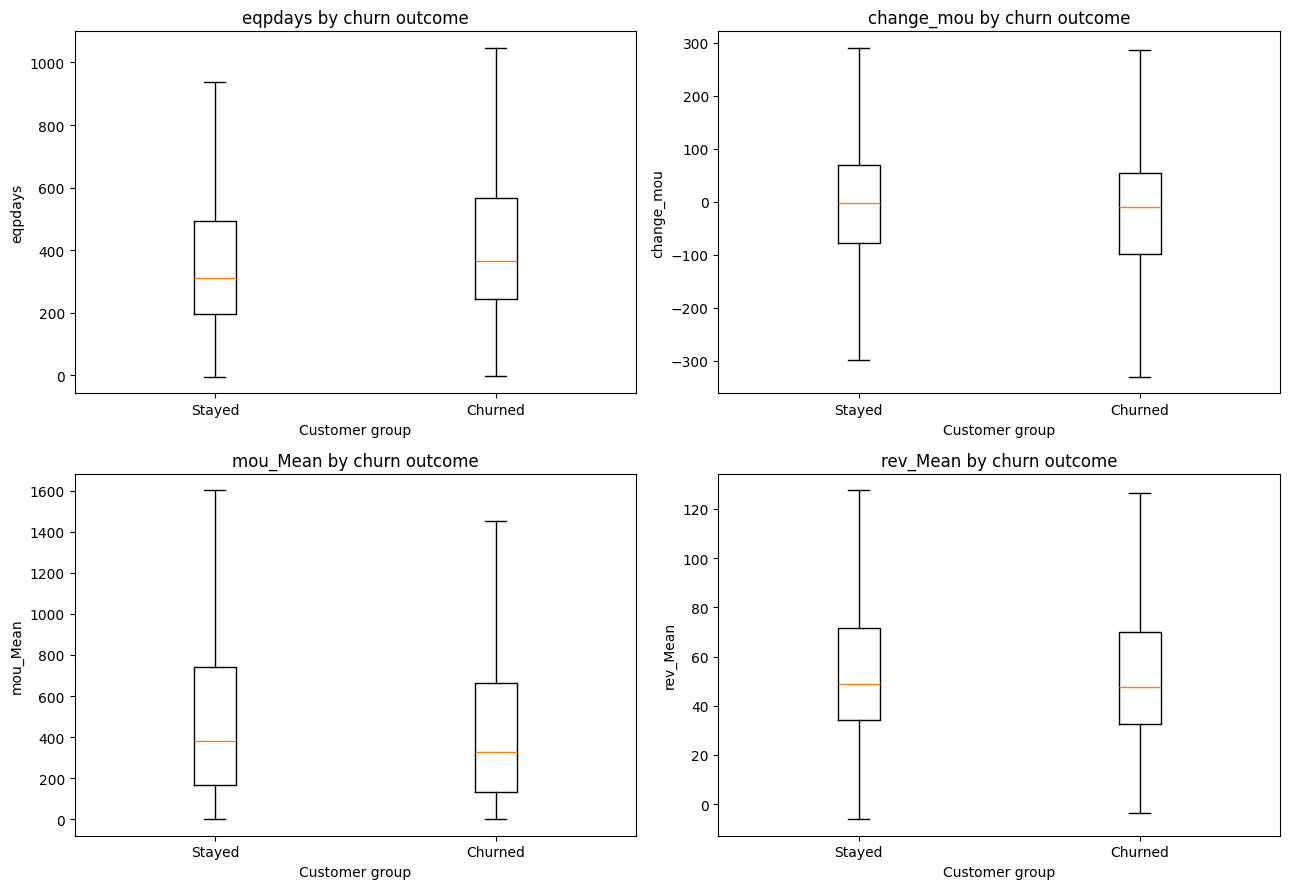

In [32]:
plot_features = [col for col in ["eqpdays", "change_mou", "mou_Mean", "rev_Mean"] if col in df.columns]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(plot_features, axes.flat):
    grouped_values = [
        df.loc[df[TARGET] == churn_value, feature].dropna().values
        for churn_value in [0, 1]
    ]
    try:
        ax.boxplot(grouped_values, tick_labels=["Stayed", "Churned"], showfliers=False)
    except TypeError:
        ax.boxplot(grouped_values, labels=["Stayed", "Churned"], showfliers=False)
    ax.set_title(f"{feature} by churn outcome")
    ax.set_xlabel("Customer group")
    ax.set_ylabel(feature)
for ax in axes.flat[len(plot_features):]:
    ax.remove()
plt.tight_layout()

# Save chart
save_chart(fig, "boxplot.png")
plt.show()

### What I noticed in the data

- Customers who churned had a higher median equipment age (`eqpdays`).
- Their average `change_mou` was more negative, which shows a bigger drop in monthly usage.
- Customers who stayed had higher median monthly usage (`mou_Mean`).
- Median monthly revenue (`rev_Mean`) was quite close for the two groups, so I would not treat it as a strong difference on its own.
- Churned customers did not have more customer-care calls on average. Based on this comparison, I cannot say that more customer-care calls are linked to higher churn.

These are patterns I noticed from the data. I use the model in the next sections to check whether several customer details together can help predict churn.


## 6. Choose the model inputs and split the data


I use `churn` as the value I want to predict. I remove `Customer_ID` from the input columns because it is only a customer identifier.

I split the data into three parts:

- **60% training:** I use this part to prepare the data and train the models.
- **20% validation:** I use this part to compare the models and choose one.
- **20% test:** I keep this part separate until the final evaluation.

I use stratification so the shares of customers who stayed and churned remain similar in each group.


In [10]:
# Separate the value I want to predict from the input columns.
y = df[TARGET].copy()
X = df.drop(columns=[TARGET, KEY]).copy()

X_train_validation, X_test, y_train_validation, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_validation,
    y_train_validation,
    test_size=0.25,  # This gives 20% of the full dataset for validation.
    random_state=RANDOM_STATE,
    stratify=y_train_validation,
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_validation), len(X_test)],
    "share_of_dataset_percent": [len(X_train) / len(X) * 100,
                                  len(X_validation) / len(X) * 100,
                                  len(X_test) / len(X) * 100],
    "churn_rate_percent": [y_train.mean() * 100,
                           y_validation.mean() * 100,
                           y_test.mean() * 100],
}, index=["Training", "Validation", "Test"])

print("Predictor columns:", X.shape[1])
print("Numeric predictors:", X.select_dtypes(include=np.number).shape[1])
print("Categorical predictors:", X.select_dtypes(exclude=np.number).shape[1])
display(split_summary.round(2))

Predictor columns: 98
Numeric predictors: 77
Categorical predictors: 21


,rows,share_of_dataset_percent,churn_rate_percent
Training,60000,60.000,49.560
Validation,20000,20.000,49.560
Test,20000,20.000,49.560


## 7. Prepare the data for each model

I handle number columns and category columns in different ways:

- For number columns, I fill missing values with the median. I also scale these columns for Logistic Regression.
- For category columns, I fill missing values with the most common value, then use one-hot encoding to turn the categories into numbers.
- If a new category appears in the validation or test data, the encoder can handle it without stopping the process.
- I do not scale the number columns for Decision Tree or Random Forest because these models do not need it.

I put these steps in a `Pipeline` and `ColumnTransformer`. This also makes sure the data preparation is fitted on the training data only.


In [11]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Support both newer and older Scikit-learn versions.
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)


def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(steps=numeric_steps)
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder()),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        remainder="drop",
    )

## 8. Compare the models using the validation data


I compare four models:

1. **Dummy Classifier:** a simple baseline. The other models should do better than this.
2. **Logistic Regression:** a basic classification model from Session 5.
3. **Decision Tree:** a tree-based model from Session 5.
4. **Random Forest:** a group of decision trees working together. This is the main model I want to test.

I use a basic Random Forest setup. I have not tried every possible setting, so there may be room to improve it later.

I compare the models using accuracy, precision, recall, F1, ROC-AUC, and PR-AUC. The first four use a 0.50 prediction threshold. ROC-AUC and PR-AUC use the predicted probabilities.


In [12]:
model_pipelines = {
    "Dummy Baseline": Pipeline([
        ("classifier", DummyClassifier(strategy="prior")),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("classifier", LogisticRegression(max_iter=2000, solver="lbfgs")),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=False)),
        ("classifier", DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=50,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=False)),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ]),
}

validation_probabilities = {}
validation_rows = []

for model_name, pipeline in model_pipelines.items():
    print("START", model_name, flush=True)
    # Limit the number of threads used while fitting each model.
    with threadpool_limits(limits=1):
        pipeline.fit(X_train, y_train)
        print("FIT DONE", model_name, flush=True)
        probabilities = pipeline.predict_proba(X_validation)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)
    validation_probabilities[model_name] = probabilities

    validation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1": f1_score(y_validation, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_validation, probabilities),
        "PR-AUC": average_precision_score(y_validation, probabilities),
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    by=["ROC-AUC", "PR-AUC"], ascending=False
).reset_index(drop=True)
display(validation_results.round(4))

START Dummy Baseline
FIT DONE Dummy Baseline
START Logistic Regression
FIT DONE Logistic Regression
START Decision Tree
FIT DONE Decision Tree
START Random Forest
FIT DONE Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.626,0.621,0.631,0.626,0.676,0.659
1,Decision Tree,0.588,0.588,0.566,0.576,0.630,0.609
2,Logistic Regression,0.598,0.594,0.592,0.593,0.629,0.602
3,Dummy Baseline,0.504,0.000,0.000,0.000,0.500,0.496


Saved: Candidate Model Comparison - Validation Set.png


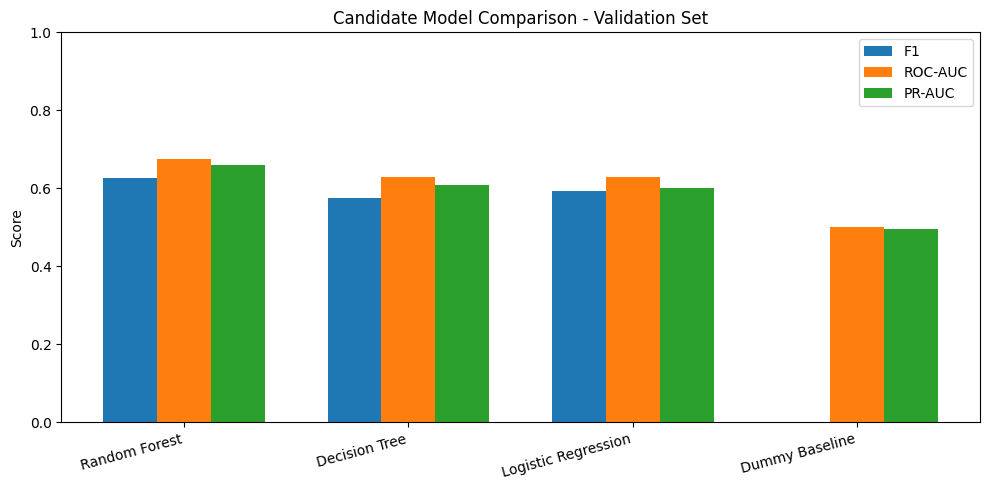

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
metric_names = ["F1", "ROC-AUC", "PR-AUC"]
model_names = validation_results["Model"].tolist()
positions = np.arange(len(model_names))
bar_width = 0.24
for metric_index, metric_name in enumerate(metric_names):
    values = validation_results.set_index("Model").loc[model_names, metric_name].values
    ax.bar(positions + (metric_index - 1) * bar_width, values, width=bar_width, label=metric_name)
ax.set_xticks(positions)
ax.set_xticklabels(model_names, rotation=15, ha="right")
ax.set_title("Candidate Model Comparison - Validation Set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
# Save chart
save_chart(fig, "Candidate Model Comparison - Validation Set.png")
plt.show()

### How I chose the model

I use the validation results to choose the model. I do not use the final test results to make this choice.

I mainly compare ROC-AUC because I want to see how well each model ranks customers by churn risk. I also check PR-AUC because it shows the balance between finding customers who churn and avoiding too many incorrect alerts.

The precision, recall, and F1 scores use the default 0.50 threshold. The company would need to choose a suitable threshold based on how many customers it can contact and how much a retention offer costs.


In [14]:
best_model_name = validation_results.iloc[0]["Model"]
print("Selected model based on validation ROC-AUC, with PR-AUC as a secondary check:", best_model_name)

Selected model based on validation ROC-AUC, with PR-AUC as a secondary check: Random Forest


## 9. Evaluate the selected model on the untouched test data


I keep the selected model as it was trained on the 60% training data. I used the validation data to choose the model, so I do not add it to the training data for this evaluation.

I use the test data only once at this stage. This gives me a final check using records that were not used to train or choose the model. If the company wanted to develop a model for actual use, it could later be trained again using both the training and validation data.


In [15]:
# This model was trained using the training data.
# Keep it unchanged for the final test.
final_model = model_pipelines[best_model_name]

with threadpool_limits(limits=1):
    test_probabilities = final_model.predict_proba(X_test)[:, 1]
TEST_THRESHOLD = 0.50
test_predictions = (test_probabilities >= TEST_THRESHOLD).astype(int)

final_test_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Threshold": TEST_THRESHOLD,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities),
}])

display(final_test_metrics.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.500,0.622,0.616,0.633,0.624,0.672,0.653


In [16]:
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, test_predictions))
print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed (0)", "Churned (1)"],
    digits=4,
    zero_division=0,
))

Confusion matrix (rows = actual, columns = predicted):
[[6178 3910]
 [3642 6270]]

Classification report:
              precision    recall  f1-score   support

  Stayed (0)     0.6291    0.6124    0.6207     10088
 Churned (1)     0.6159    0.6326    0.6241      9912

    accuracy                         0.6224     20000
   macro avg     0.6225    0.6225    0.6224     20000
weighted avg     0.6226    0.6224    0.6224     20000



Saved: Final Test Set - Confusion Matrix.png


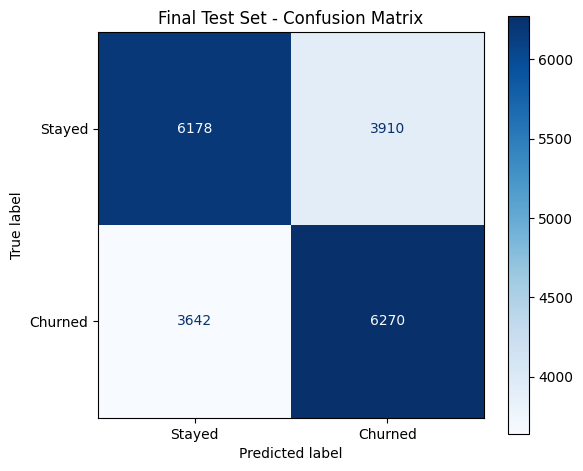

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set_title("Final Test Set - Confusion Matrix")
plt.tight_layout()

# Save chart
save_chart(fig, "Final Test Set - Confusion Matrix.png")

plt.show()

Saved: ROC Curve and Precision-Recall Curve.png


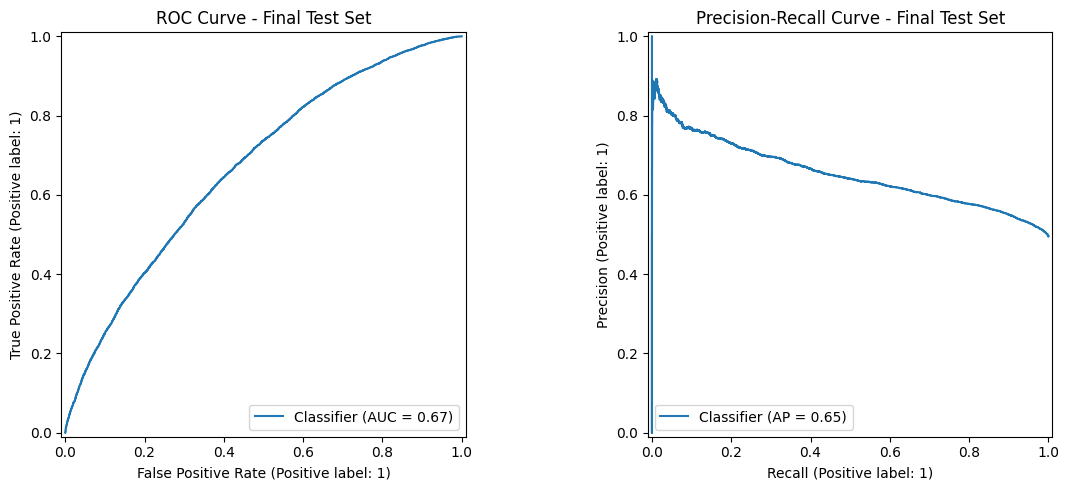

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[0])
axes[0].set_title("ROC Curve - Final Test Set")
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[1])
axes[1].set_title("Precision-Recall Curve - Final Test Set")
plt.tight_layout()

# Save chart
save_chart(fig, "ROC Curve and Precision-Recall Curve.png")
plt.show()

### What the scores mean

- **Accuracy:** the share of all customers the model classified correctly.
- **Precision:** out of the customers the model flagged as likely to churn, how many actually churned.
- **Recall:** out of all customers who churned, how many the model found.
- **F1:** one score that balances precision and recall.
- **ROC-AUC:** how well the model ranks customers who churned above customers who stayed.
- **PR-AUC:** another way to check the balance between precision and recall.

The AUC results are around 0.68. This shows that the model has found some useful patterns, but it still has limits when separating customers who churn from those who stay. I would use it as a starting point to help staff review customers, not as a system that makes decisions on its own.


## 10. Check different prediction thresholds


The model uses 0.50 as the default threshold. A lower threshold usually flags more customers. This may help find more customers who will churn, but it can also create more incorrect alerts. A higher threshold usually flags fewer customers, but it may miss some customers who will churn.

I compare a few thresholds using the validation data. This table is only a guide. The company would need to choose a threshold based on its campaign budget, the number of customers it can contact, and the value of keeping those customers.


In [19]:
validation_best_probabilities = validation_probabilities[best_model_name]
threshold_rows = []
for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_predictions = (validation_best_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "customers_flagged_percent": threshold_predictions.mean() * 100,
        "precision": precision_score(y_validation, threshold_predictions, zero_division=0),
        "recall": recall_score(y_validation, threshold_predictions, zero_division=0),
        "f1": f1_score(y_validation, threshold_predictions, zero_division=0),
    })

display(pd.DataFrame(threshold_rows).round(4))

,threshold,customers_flagged_percent,precision,recall,f1
0,0.300,93.560,0.516,0.974,0.674
1,0.400,79.395,0.553,0.887,0.681
2,0.500,50.355,0.621,0.631,0.626
3,0.600,17.850,0.708,0.255,0.375
4,0.700,3.410,0.824,0.057,0.106


## 11. Check which features were important

This section shows which features the Random Forest used most when making its predictions. I combine the one-hot encoded category columns so the results are shown using the original column names.

These scores do not show whether a feature increases or decreases churn. They also do not prove that a feature causes churn. Some features may appear more important because they have many possible values, and similar features can share importance. I could use permutation importance or SHAP in a future version to look into this further.


,feature,importance
0,eqpdays,0.040
1,months,0.032
2,change_mou,0.028
3,adjrev,0.022
4,mou_Mean,0.021
5,totrev,0.021
6,avgqty,0.020
7,avgrev,0.020
8,change_rev,0.020
9,avgmou,0.020


Saved: Top 15 Aggregated Feature Importances.png


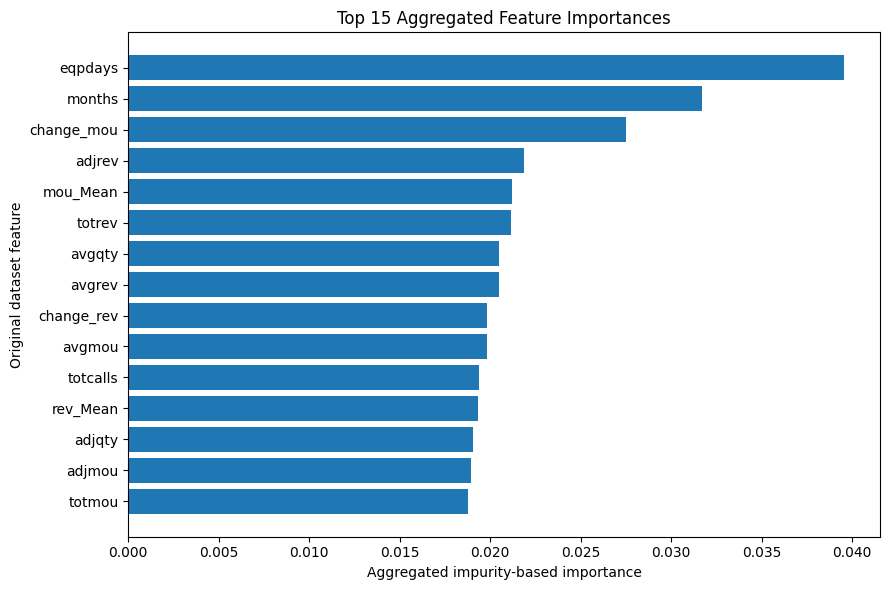

In [28]:
selected_estimator = final_model.named_steps.get("classifier")

if hasattr(selected_estimator, "feature_importances_"):
    fitted_preprocessor = final_model.named_steps["preprocessor"]
    encoded_feature_names = fitted_preprocessor.get_feature_names_out()
    encoded_importances = selected_estimator.feature_importances_

    raw_importance = {}
    categorical_names = sorted(categorical_features, key=len, reverse=True)

    for encoded_name, importance_value in zip(encoded_feature_names, encoded_importances):
        if encoded_name.startswith("numeric__"):
            raw_name = encoded_name.replace("numeric__", "", 1)
        elif encoded_name.startswith("categorical__"):
            encoded_suffix = encoded_name.replace("categorical__", "", 1)
            raw_name = next(
                (column for column in categorical_names
                 if encoded_suffix == column or encoded_suffix.startswith(column + "_")),
                encoded_suffix,
            )
        else:
            raw_name = encoded_name

        raw_importance[raw_name] = raw_importance.get(raw_name, 0.0) + float(importance_value)

    feature_importance = (
        pd.Series(raw_importance, name="importance")
          .sort_values(ascending=False)
          .rename_axis("feature")
          .reset_index()
    )
    display(feature_importance.head(15).round(5))

    plot_importance = feature_importance.head(15).sort_values("importance")
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(plot_importance["feature"], plot_importance["importance"])
    ax.set_title("Top 15 Aggregated Feature Importances")
    ax.set_xlabel("Aggregated impurity-based importance")
    ax.set_ylabel("Original dataset feature")
    plt.tight_layout()
    # Save chart
    save_chart(fig, "Top 15 Aggregated Feature Importances.png")
    plt.show()
else:
    print("The selected model does not expose tree-based feature_importances_.")
    print("Use permutation importance or model-specific explanations instead.")

## 12. What the results could mean for the business

Based on the patterns in the data and the model results, I would suggest testing these actions:

1. **Device upgrade offers:** review high-risk customers who have older equipment and test whether an upgrade offer helps them stay.
2. **Usage drop follow-up:** check on high-risk customers whose usage has dropped. The company should first find out whether the drop is linked to a service issue, a plan change, seasonality, or a change in the customer's needs.
3. **Customer groups:** use the risk scores to help decide which customers staff should review first. A high score does not mean the customer will definitely leave.
4. **Test retention campaigns:** use a test group and a comparison group to see whether an offer really helps keep more customers. A churn model can identify risk, but it cannot tell us whether an offer will stop someone from leaving.

### About customer-care calls

In this dataset, customers who churned had fewer customer-care calls on average than customers who stayed. Based on this result, I should not say that more customer-care calls are a reason for churn.


## 13. Example of possible business impact

The dataset has 49,562 customers who churned. As an example, a 5% reduction in that number would be about 2,478 customers:

`49,562 × 5% = approximately 2,478 customers`.

This is only an example based on an assumption. It does not mean the model will save 2,478 customers. To estimate the real impact, the company would need to know the campaign cost, customer value, response rate, and how many customers stayed because of the campaign.


## 14. Limits of this project and what I could do next

### Current limits

- The dataset is anonymous, and the data guide does not explain every column. I would need to check that all input columns are available before the churn outcome is recorded.
- The churn rate in this dataset may be different from the company's current churn rate.
- Some columns have many missing values. Filling them with the median or most common value is a starting point, but I could test other ways to handle them.
- The model's performance is moderate. Staff should review the results before the company spends money on retention offers.
- I have not chosen a prediction threshold based on the company's costs or campaign limits.
- I used a random split. Testing on data from a later time period would give a better idea of how the model may work in the future.
- The model can find patterns, but it cannot prove what causes churn or whether a campaign will work.

### What I could do next

1. Check that all model inputs are available before the 31–60 day churn period.
2. Try more model settings and compare the results using the training and validation data.
3. Check whether the predicted probabilities are reliable and choose a threshold that fits the company's needs.
4. Test the model on newer data and keep checking its performance.
5. Run a controlled campaign test to see whether the offers help retain more customers.

---

## 15. Optional: cross-validation check

Session 8 covers cross-validation. I added an optional three-fold check below to see how the selected model performs across different training and validation splits. It may take longer to run. The final test data is not included.


In [21]:
# Change this to True if I want to run the extra cross-validation check.
RUN_OPTIONAL_CV = False

if RUN_OPTIONAL_CV:
    from sklearn.model_selection import StratifiedKFold, cross_validate

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    cv_pipeline = model_pipelines[best_model_name]
    cv_results = cross_validate(
        cv_pipeline,
        X_train_validation,
        y_train_validation,
        cv=cv,
        scoring={"roc_auc": "roc_auc", "f1": "f1", "average_precision": "average_precision"},
        n_jobs=1,
        return_train_score=False,
    )

    pd.DataFrame({
        "metric": ["ROC-AUC", "F1", "PR-AUC"],
        "mean": [
            cv_results["test_roc_auc"].mean(),
            cv_results["test_f1"].mean(),
            cv_results["test_average_precision"].mean(),
        ],
        "standard_deviation": [
            cv_results["test_roc_auc"].std(),
            cv_results["test_f1"].std(),
            cv_results["test_average_precision"].std(),
        ],
    }).round(4)
else:
    print("Skipped. Set RUN_OPTIONAL_CV = True when you want to run the additional cross-validation check.")

Skipped. Set RUN_OPTIONAL_CV = True when you want to run the additional cross-validation check.


## Final conclusion

In this project, I combined the two customer files, checked the data, explored customer patterns, compared classification models, and used the results to suggest possible retention actions.

I keep Random Forest as the selected model if it has the best validation result. I report its test results exactly as shown in this notebook. The model is a starting point that may help the company decide which customers to review first. It is not ready to make retention decisions on its own.


# Exporting Charts and Tables

In [22]:
# Create a folder for the charts
CHART_DIR = DATA_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

# Function to save each chart
def save_chart(fig, filename):
    output_path = CHART_DIR / filename
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {filename}")

In [35]:
import shutil
from google.colab import files

# Create a ZIP containing all exported charts
zip_path = shutil.make_archive(
    str(DATA_DIR / "Company_A_Churn_Charts"),
    "zip",
    CHART_DIR
)

# Download the ZIP
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
# Create a folder for the exported tables
TABLE_DIR = DATA_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Prepare the tables
behavior_table = feature_group_summary.pivot(
    index="feature",
    columns="customer_group",
    values=["mean", "median"]
).round(2)

threshold_table = pd.DataFrame(threshold_rows).round(4)

confusion_table = pd.DataFrame(
    confusion_matrix(y_test, test_predictions),
    index=["Actual Stayed", "Actual Churned"],
    columns=["Predicted Stayed", "Predicted Churned"]
)

classification_table = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Stayed", "Churned"],
        output_dict=True
    )
).T

tables = {
    "Churn Distribution": churn_summary,
    "Missing Values": missing_summary.head(20),
    "Customer Behavior": behavior_table,
    "Dataset Split": split_summary,
    "Model Comparison": validation_results,
    "Final Test Metrics": final_test_metrics,
    "Confusion Matrix": confusion_table,
    "Threshold Analysis": threshold_table,
    "Feature Importance": feature_importance.head(15),
    "Classification Report": classification_table
}

# Export everything into one Excel workbook
excel_path = TABLE_DIR / "Company_A_Churn_Tables.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, table in tables.items():
        table.to_excel(writer, sheet_name=sheet_name)

print("All tables exported successfully!")
print("Saved to:", excel_path)

All tables exported successfully!
Saved to: /content/drive/MyDrive/Colab Notebooks/GCI WORLD FINAL ASSIGNMENT/tables/Company_A_Churn_Tables.xlsx
